# SIFSM — Simulação e análise do consumo de energia da colônia

**equipe — Simulação e análise de dados (Matemática e previsão)**

Este notebook demonstra como os dados da colônia ajudam a **prever cenários** e **tomar decisões**.
Toda a lógica está nos módulos de `src/` (reutilizados pelo sistema principal); aqui executamos e interpretamos.

| Etapa | Onde |
|---|---|
| 2.1 Fenômeno · 2.2 Variáveis e hipóteses | Seção 1 |
| 2.3 Simulação computacional | Seção 2 |
| 2.4 Integração numérica | Seção 3 |
| 2.5 Gráficos · 2.6 Análise exploratória | Seções 2–4 |
| 2.7 Regressão linear · 2.8 Avaliação | Seções 5–6 |
| 2.9 Resultados para o sistema principal | Seção 7 |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
from IPython.display import Image, display

import simulacao_energia as sim
import regressao_linear as rl
import analise_simulacao as analise

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
mostrar = lambda nome: display(Image(filename=str(RAIZ / "docs" / "graficos" / nome)))

## 1. Fenômeno, variáveis e hipóteses (2.1 e 2.2)

**Fenômeno:** balanço energético da colônia ao longo de **120 sóis** (dia marciano = 24,66 h), com passo de 15 min.
A energia consumida pelos módulos é comparada com a energia gerada; a diferença carrega ou descarrega a bateria.

**Dados de entrada:** os módulos cadastrados no sistema principal (`data/dados_teste.json`, mesmos campos da tabela `MODULOS`):
`consumo_kwh` vira a carga base (kW), `temperatura_c` é a temperatura interna a manter e `status` ajusta a carga.

**Variáveis**

| Tipo | Variável | Valor / faixa |
|---|---|---|
| Entrada | Temperatura externa | média −60 °C, ±12 °C sazonal, ±35 °C dia/noite |
| Entrada | Tripulantes | 6 a 14, troca de turno a cada 5 sóis |
| Entrada | Tempestade de poeira | sóis 70–79, bloqueia 65% da luz |
| Entrada | Painéis / reator / bateria | 7.000 m² (22%) / 40 kW / 6.000 kWh |
| Saída | Consumo e geração (kW, kWh) | por passo e por sol |
| Saída | Estado de carga (SOC) e alerta | 0–100% · booleano |

**Hipóteses (simplificações)**
1. Aquecimento proporcional à diferença de temperatura: `P_aq = 0,35 kW/°C × (T_interna − T_externa)` por módulo.
2. Cada tripulante acordado (7h–23h) consome 2,5 kW no módulo habitacional.
3. Módulo em `MANUTENCAO` opera com 60% da carga base; `INATIVO` não consome.
4. Irradiância solar é uma meia senoide durante o dia (pico de 500 W/m²).
5. A bateria não perde energia; falta de energia é registrada como *energia não suprida*.
6. Ruídos aleatórios (com semente fixa) representam variações operacionais — a simulação é reprodutível.

In [2]:
p = sim.ParametrosSimulacao()
modulos = sim.carregar_modulos()
pd.DataFrame(modulos)

,id,nome,tipo,consumo_kwh,temperatura_c,status
0,1,Módulo Habitacional A,HABITACAO,35.50,22.00,ATIVO
1,2,Módulo Agrícola A,AGRICULTURA,42.00,24.50,ATIVO
2,3,Módulo Laboratório A,LABORATORIO,120.00,27.00,MANUTENCAO


## 2. Simulação computacional (2.3)

In [3]:
serie, diario = sim.simular(p, modulos)
print(f"{len(serie):,} passos de tempo · {len(diario)} sóis")
serie.head()

11,837 passos de tempo · 120 sóis


,tempo_h,sol,hora_sol,temp_ext_c,irradiancia_w_m2,tripulantes,tempestade,potencia_habitacao_kw,potencia_agricultura_kw,potencia_laboratorio_kw,consumo_kw,geracao_solar_kw,geracao_total_kw,saldo_kw,consumo_acumulado_kwh,energia_bateria_kwh,soc,energia_nao_suprida_kwh,energia_desperdicada_kwh,alerta_energia
0,0.00,0,0.00,-97.35,0.00,11,False,81.87,81.21,112.88,275.96,0.00,40.00,-235.96,0.00,"3,600.00",0.60,0.00,0.00,False
1,0.25,0,0.25,-98.76,0.00,11,False,76.01,86.35,111.28,273.64,0.00,40.00,-233.64,68.70,"3,541.30",0.59,0.00,0.00,False
2,0.50,0,0.50,-100.07,0.00,11,False,78.21,86.46,117.96,282.63,0.00,40.00,-242.63,138.23,"3,481.77",0.58,0.00,0.00,False
3,0.75,0,0.75,-101.26,0.00,11,False,81.05,85.24,120.61,286.91,0.00,40.00,-246.91,209.43,"3,420.57",0.57,0.00,0.00,False
4,1.00,0,1.00,-102.33,0.00,11,False,80.62,85.84,123.80,290.26,0.00,40.00,-250.26,281.57,"3,358.43",0.56,0.00,0.00,False


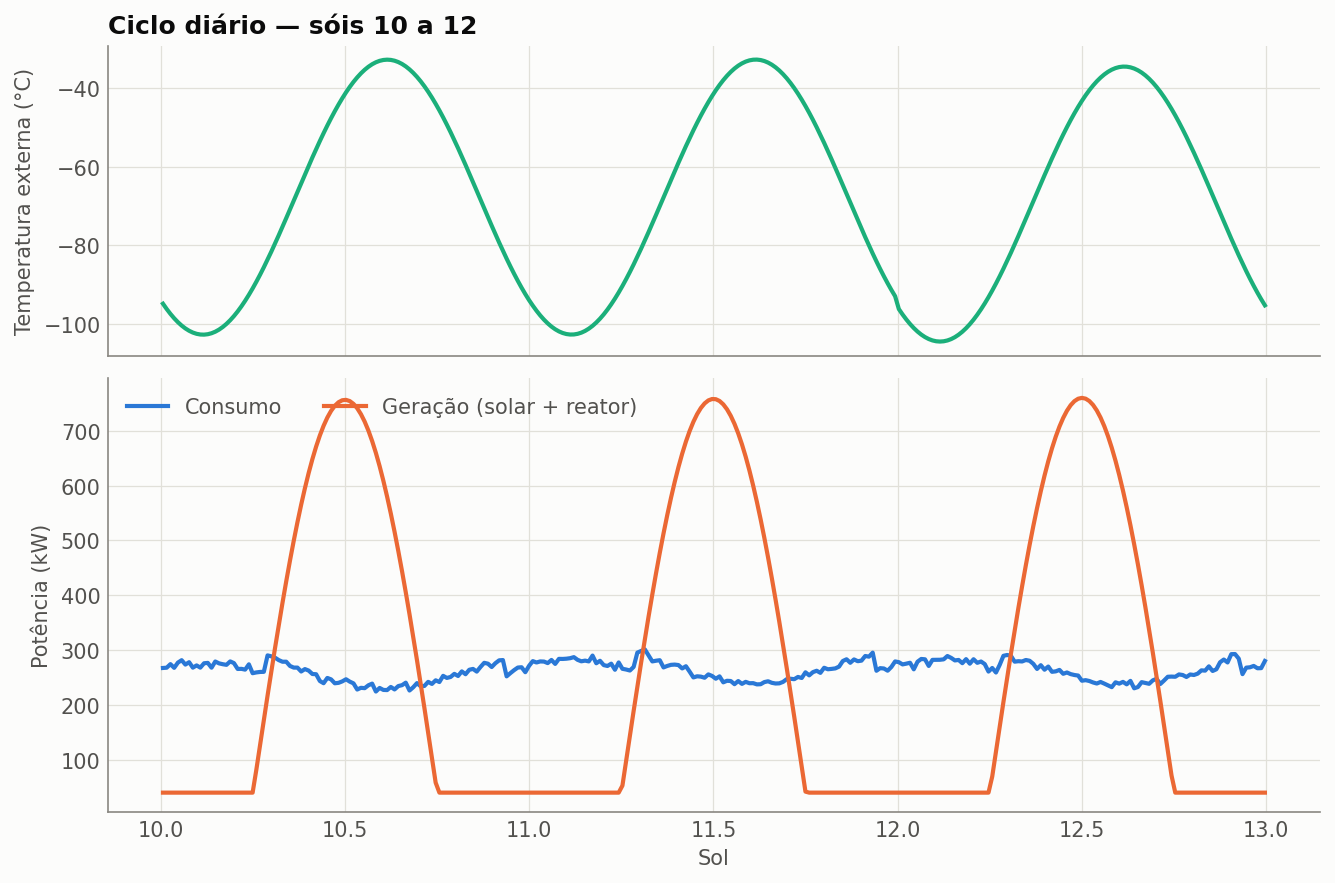

In [4]:
resultados = analise.executar(verbose=False)   # gera CSVs, gráficos e JSON
mostrar("01_ciclo_diario.png")

No ciclo diário, a geração solar supera o consumo durante o dia e cai para o patamar do reator (40 kW) à noite.
A bateria precisa cobrir a noite inteira — o ponto crítico do sistema.

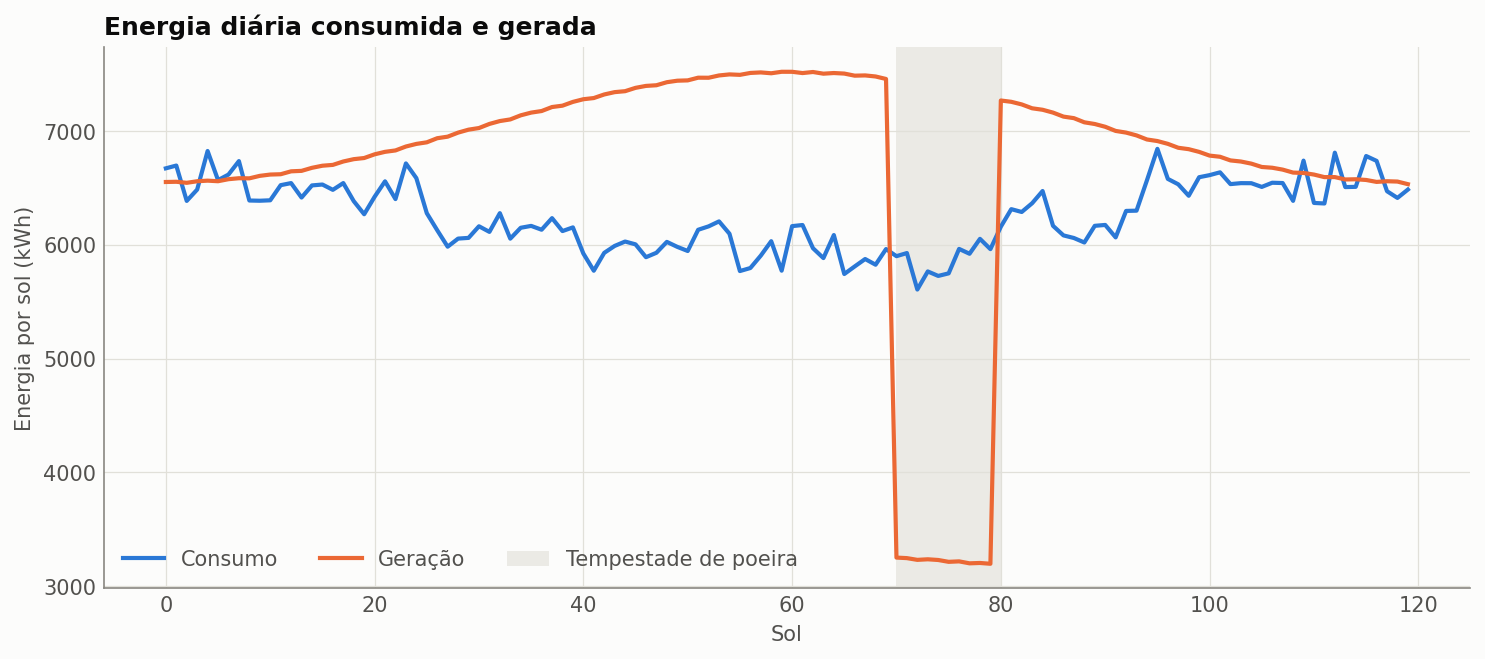

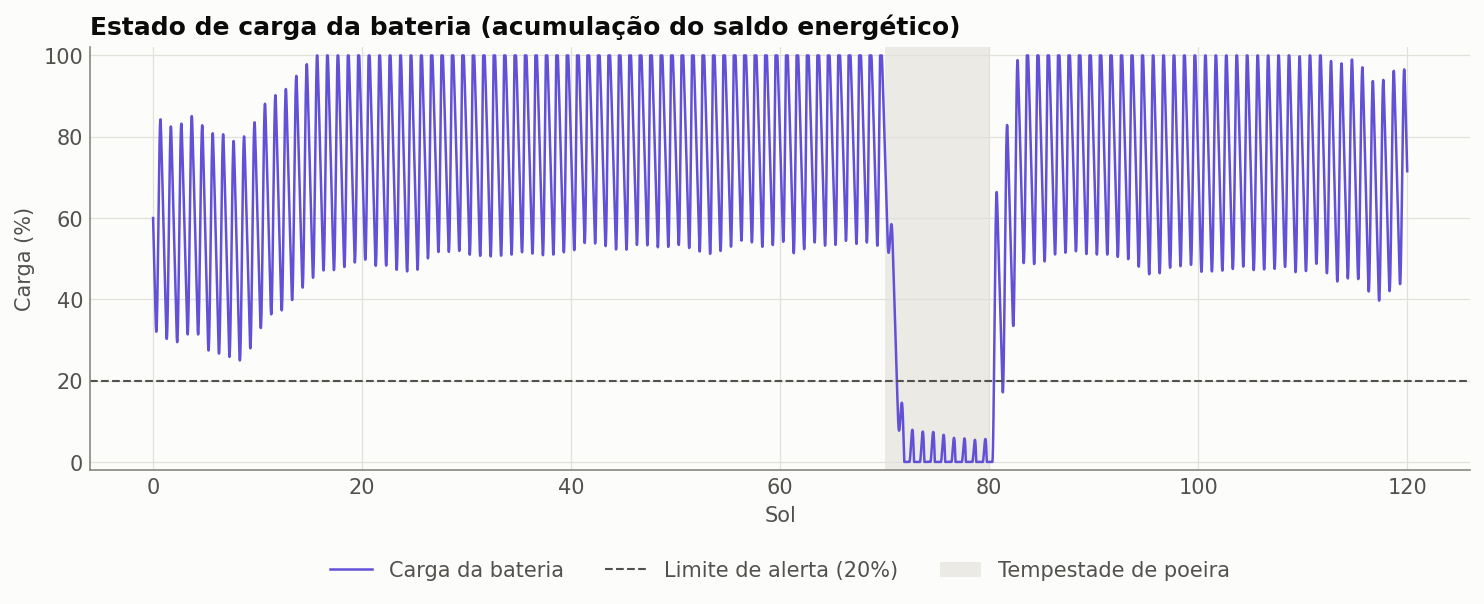

In [5]:
mostrar("02_balanco_diario.png")
mostrar("03_bateria.png")

## 3. Conceito matemático: integração numérica e acumulação (2.4)

Energia é a integral da potência: $E = \int P(t)\,dt$. Como a simulação só conhece $P$ em instantes discretos,
usamos a **regra dos trapézios**:

$$E \approx \sum_{k} \frac{P_k + P_{k+1}}{2}\,\Delta t$$

A **bateria** é uma acumulação: $E_{bat}(t_{k+1}) = E_{bat}(t_k) + \int_{t_k}^{t_{k+1}} (G - P)\,dt$, limitada entre 0 e a capacidade.

Para validar o método, comparamos com a integral **exata** da geração solar da manhã
($P_{max}\,\sin$ do nascer ao meio-dia, cuja integral é $P_{max} D / \pi$):

In [6]:
erros = analise.verificar_integracao(p)
erros

,dt_h,exata_kwh,trapezio_kwh,retangulos_kwh,erro_trapezio_pct,erro_retangulos_pct
0,2.06,"3,022.07","2,952.71","2,161.53",2.30,28.48
1,1.03,"3,022.07","3,004.79","2,609.20",0.57,13.66
2,0.51,"3,022.07","3,017.75","2,819.96",0.14,6.69
3,0.25,"3,022.07","3,021.07","2,926.13",0.03,3.17
4,0.10,"3,022.07","3,021.90","2,983.62",0.01,1.27


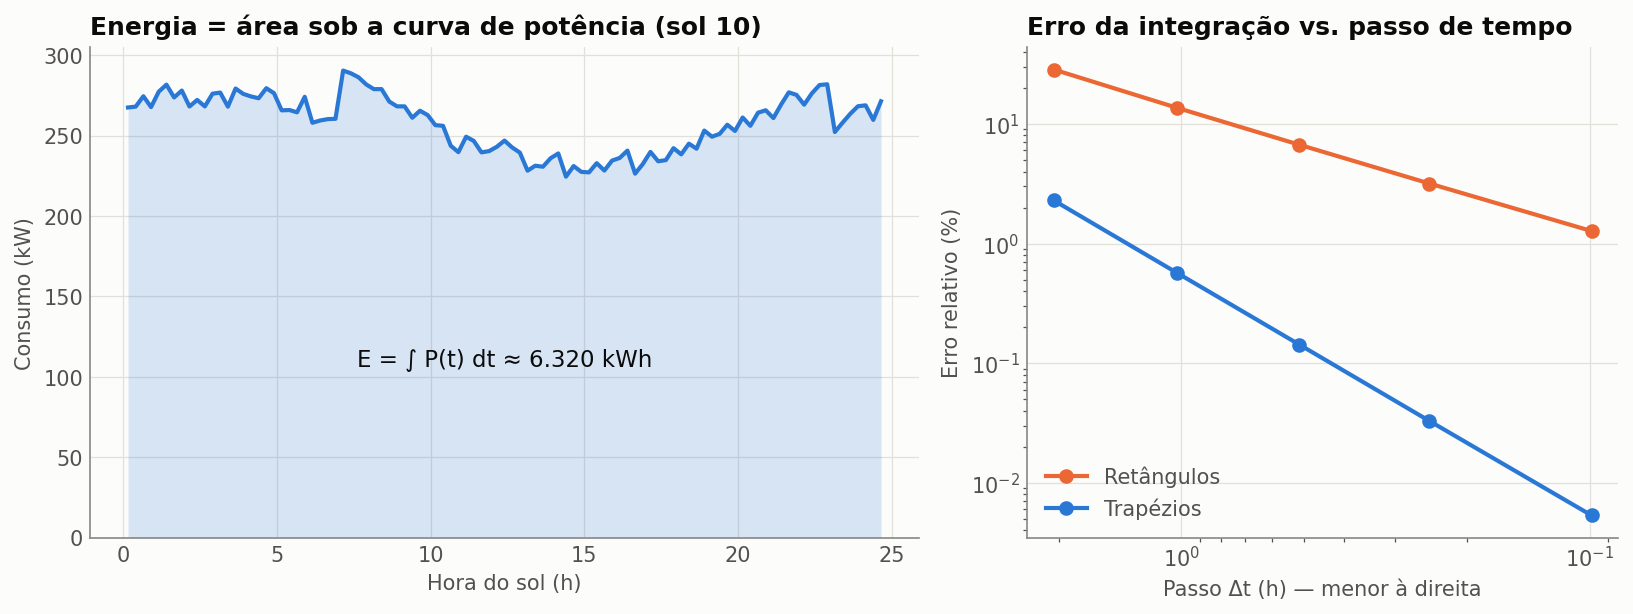

In [7]:
mostrar("04_integracao_numerica.png")

Ao dividir o passo Δt por 2, o erro do trapézio cai ~4× (método de **ordem 2**) enquanto o dos retângulos cai ~2× (**ordem 1**).
Com o passo usado na simulação (15 min), o erro do trapézio é de ~0,03% — desprezível.

## 4. Análise exploratória dos dados (2.6)

In [8]:
eda = analise.analise_exploratoria(diario)
eda["descricao"]

,count,mean,std,min,25%,50%,75%,max
consumo_kwh,120.00,"6,248.16",297.11,"5,605.72","6,014.69","6,218.35","6,510.54","6,840.85"
geracao_kwh,120.00,"6,684.28","1,097.49","3,197.83","6,615.27","6,903.87","7,268.25","7,517.63"
saldo_kwh,120.00,436.12,"1,091.44","-2,845.84",135.39,460.34,"1,151.34","1,759.93"
temp_media_c,120.00,-59.76,9.44,-77.69,-67.79,-60.24,-50.25,-43.76
tripulantes,120.00,9.54,2.59,6.00,7.00,9.50,11.25,14.00
soc_min,120.00,0.43,0.15,0.00,0.43,0.48,0.52,0.54


In [9]:
# Sóis normais (False) x sóis com tempestade (True)
eda["tempestade"]

,consumo_kwh,geracao_kwh,saldo_kwh,soc_min,horas_em_alerta
tempestade,,,,,
False,"6,283.79","6,998.87",715.07,0.47,0.12
True,"5,856.15","3,223.83","-2,632.32",0.03,21.80


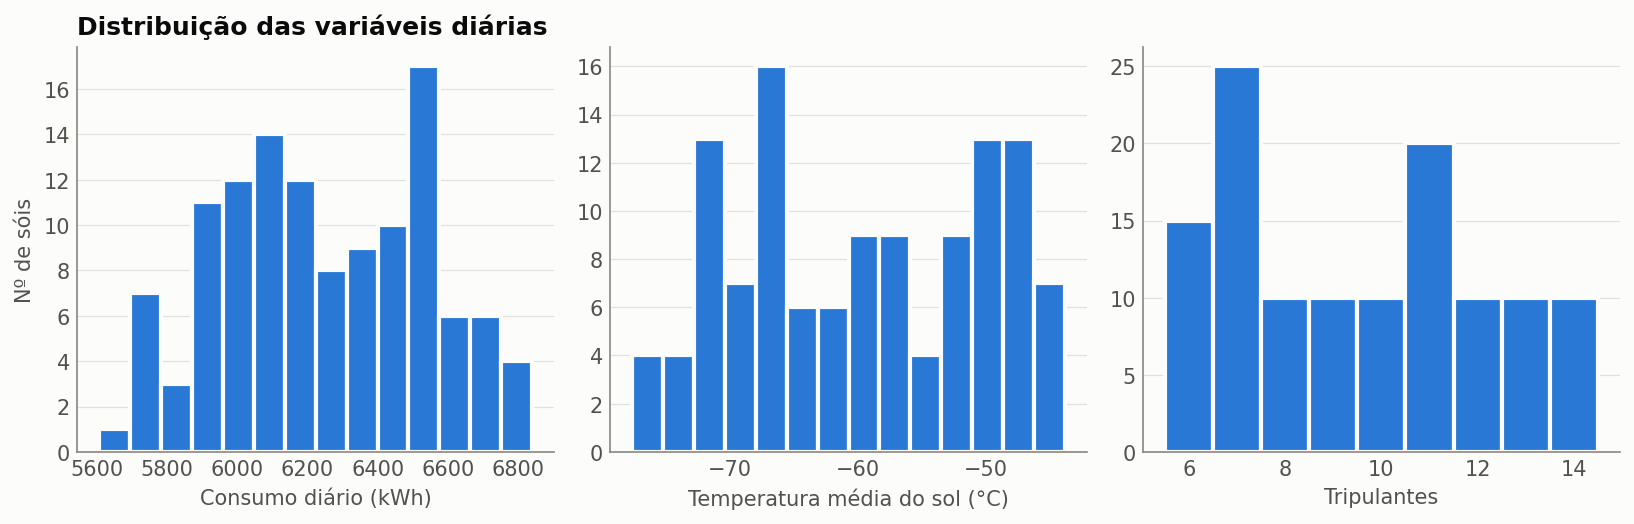

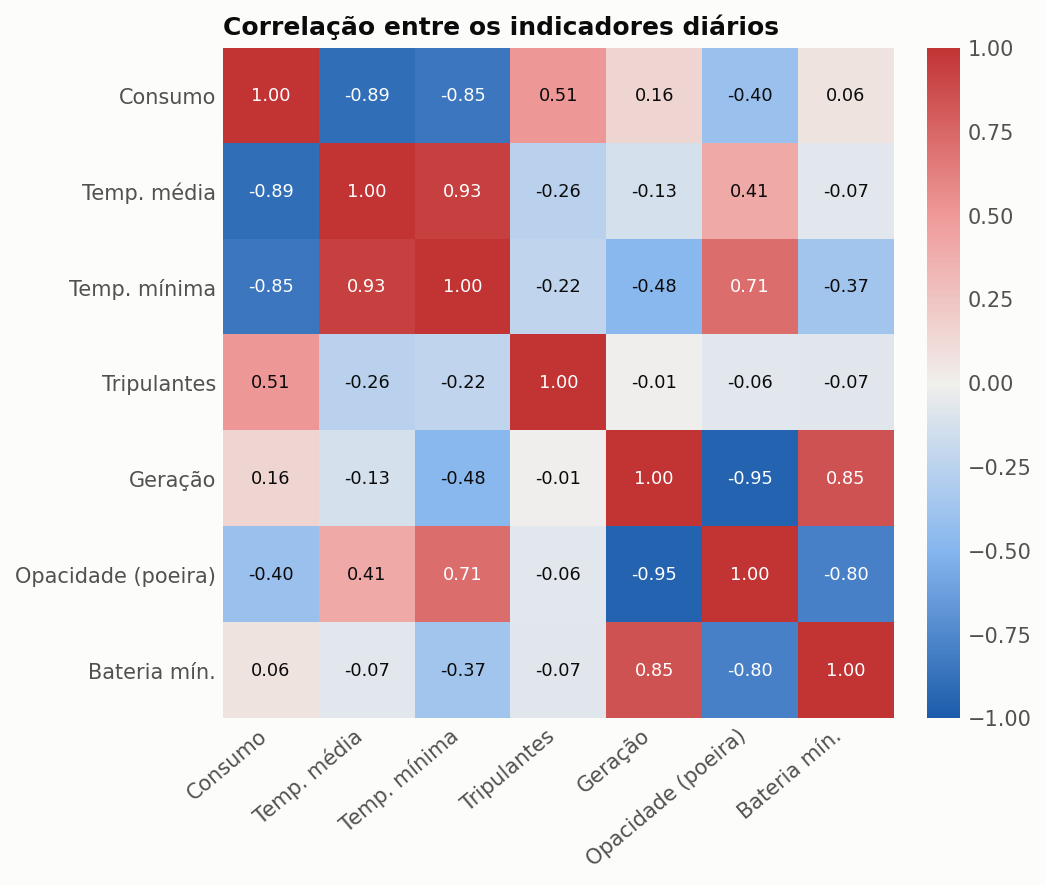

In [10]:
mostrar("05_distribuicoes.png")
mostrar("06_correlacao.png")

**Achados da exploração**
- O consumo diário varia pouco (≈ ±5%), mas a **geração** despenca na tempestade (de ~7.000 para ~3.200 kWh/sol).
- O consumo tem **correlação forte e negativa com a temperatura** (r ≈ −0,89): quanto mais frio, mais aquecimento.
- **Tripulantes** têm correlação positiva moderada (r ≈ 0,51).
- Curiosidade: na tempestade o consumo **cai** um pouco — a poeira retém calor e reduz o aquecimento — mas não compensa a perda de geração.

## 5. Regressão linear (2.7)

Indicador estimado: **consumo diário (kWh)**. Modelo múltiplo:

$$\text{consumo} = b_0 + b_1 \cdot \text{temp\_media} + b_2 \cdot \text{tripulantes}$$

Ajuste por mínimos quadrados ($b = (X^TX)^{-1}X^Ty$), com 80% dos sóis para treino e 20% para teste.

In [11]:
modelos = analise.treinar_modelos(diario)
print(resultados["regressao"]["equacao"])
modelos["multiplo"].tabela_coeficientes()

consumo_kwh = 4321.3 -26.67·temp_media_c +35.07·tripulantes


,coeficiente,erro_padrao,t,ic95_inferior,ic95_superior
intercepto,"4,321.31",70.52,61.28,"4,183.09","4,459.53"
temp_media_c,-26.67,1.14,-23.31,-28.91,-24.43
tripulantes,35.07,4.16,8.43,26.91,43.23


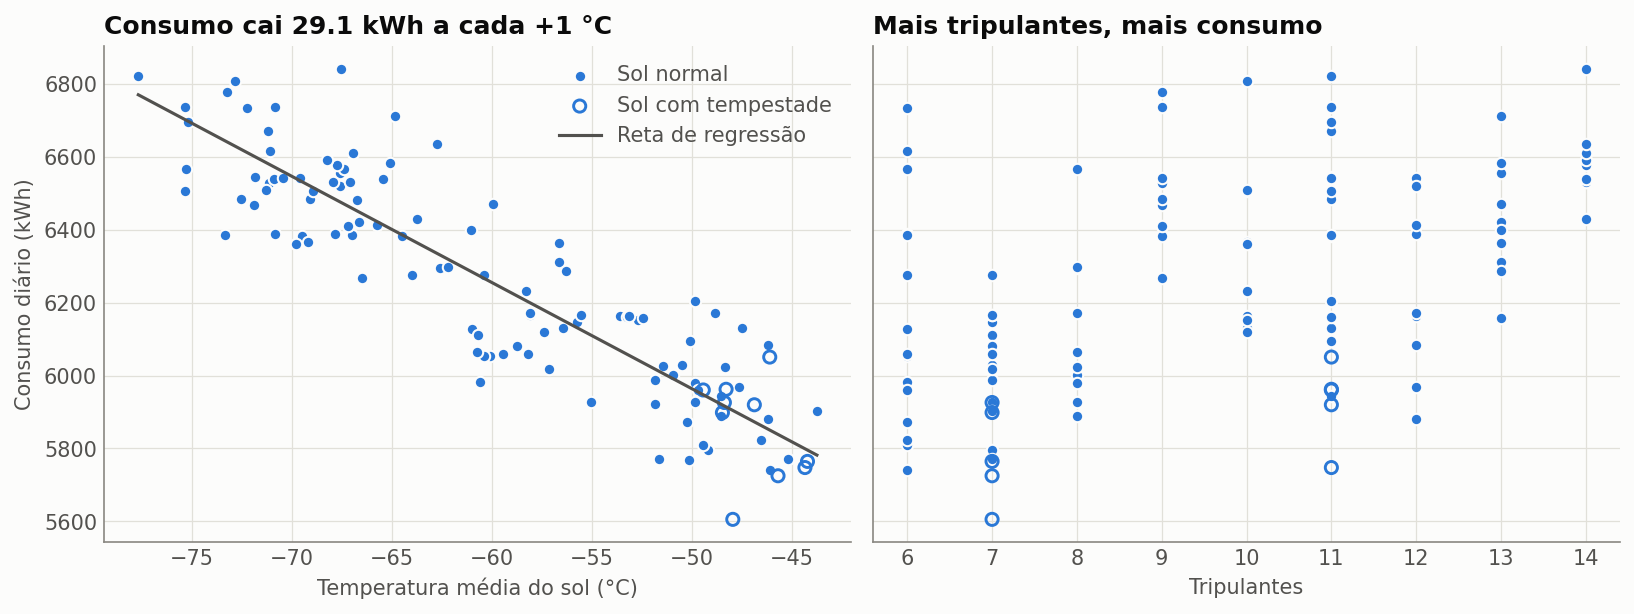

In [12]:
mostrar("07_dispersao_regressao.png")

## 6. Avaliação, interpretação e limitações (2.8)

In [13]:
linhas = []
for nome in ("simples", "multiplo"):
    for conjunto in ("treino", "teste"):
        linhas.append({"modelo": nome, "conjunto": conjunto, **modelos[f"metricas_{nome}"][conjunto]})
pd.DataFrame(linhas)

,modelo,conjunto,r2,rmse,mae,mape_pct
0,simples,treino,0.81,135.17,106.97,1.71
1,simples,teste,0.72,124.98,101.04,1.62
2,multiplo,treino,0.89,101.79,80.81,1.29
3,multiplo,teste,0.81,103.43,86.68,1.38


In [14]:
teoricos = analise.coeficientes_teoricos(p, modulos)
pd.DataFrame({"estimado": modelos["multiplo"].coeficientes, "teórico (hipóteses)": teoricos})

,estimado,teórico (hipóteses)
temp_media_c,-26.67,-25.89
tripulantes,35.07,40.00


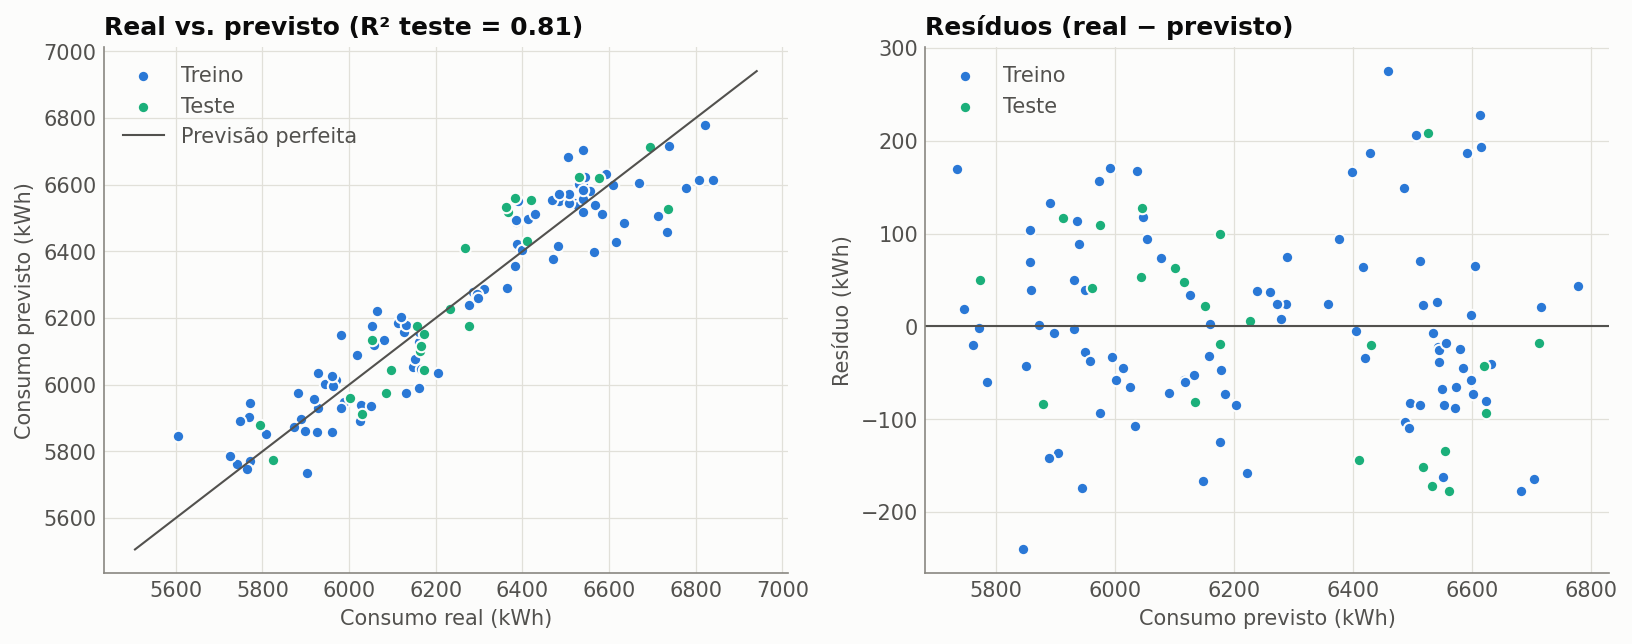

In [15]:
mostrar("08_avaliacao_modelo.png")

**Interpretação dos coeficientes**
- **b₁ ≈ −26,7 kWh/°C:** cada grau a mais na temperatura média reduz o consumo do sol em ~27 kWh (menos aquecimento).
  O valor teórico pelas hipóteses é −25,9 (3 módulos × 0,35 kW/°C × 24,66 h) — está dentro do intervalo de 95%.
- **b₂ ≈ +35 kWh/tripulante:** cada tripulante adicional acrescenta ~35 kWh por sol (teórico: 2,5 kW × 16 h = 40, também dentro do IC 95%).
- **b₀ ≈ 4.321 kWh:** sem significado físico isolado (seria 0 °C e 0 tripulantes, fora dos dados) — só ajusta o nível da reta.

**Desempenho:** R² de teste ≈ 0,81 e erro médio ≈ 1,4%. Incluir os tripulantes melhora o modelo simples (R² 0,72 → 0,81)
e corrige o coeficiente da temperatura (−29,1 → −26,7), que estava inflado por uma variável omitida.

**Limitações**
1. Dados **sintéticos**: o modelo recupera as hipóteses da própria simulação; com dados reais a relação pode ser não linear.
2. Amostra pequena (120 sóis, 96 de treino) e **uma única tempestade**.
3. Válido apenas na faixa observada (≈ −78 a −43 °C; 6 a 14 tripulantes) — fora dela é extrapolação.
4. Prevê **consumo**, não falta de energia: a falta depende da geração, que o modelo não considera.
5. Os sóis não são independentes (tripulação fixa por turno, sazonalidade), o que deixa os erros-padrão otimistas.

## 7. Apoio à decisão e resultados para o sistema principal (2.9)

Usamos a mesma simulação para testar alternativas de infraestrutura diante da tempestade:

In [16]:
pd.DataFrame(resultados["cenarios"])

,cenario,energia_nao_suprida_kwh,sois_com_falta,horas_em_alerta,soc_minimo
0,Base (reator 40 kW),"23,121.85",10,231.75,0.00
1,Painéis +20%,"18,612.01",9,217.25,0.00
2,Bateria 2x (12 MWh),"17,121.85",7,198.25,0.00
3,Reator 100 kW,"7,485.95",7,169.25,0.00
4,Reator 100 kW + bateria 2x,"1,485.95",2,63.50,0.00
5,Reator 160 kW,0.00,0,0.00,0.47


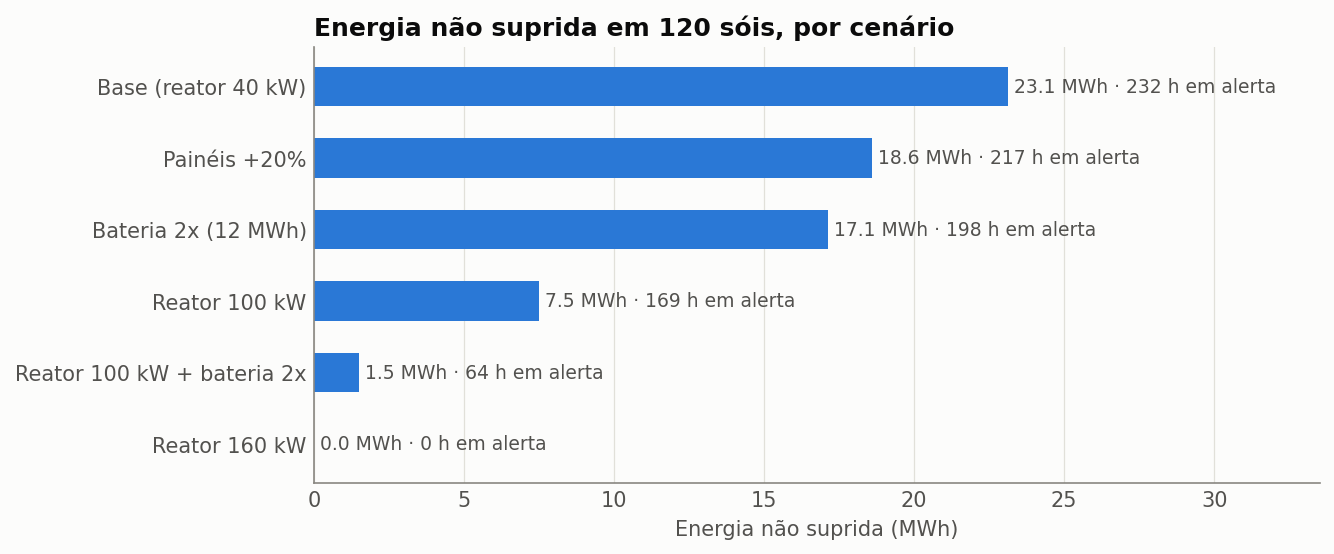

In [17]:
mostrar("09_cenarios.png")

**Leitura dos cenários:** ampliar painéis ou bateria ajuda pouco, porque a tempestade dura 10 sóis e reduz a luz.
A fonte **independente do Sol** (reator) é a que resolve: 100 kW + bateria dupla quase zera a falta; 160 kW zera.

**Integração com o SIFSM:** `analise_simulacao.py` salva `data/simulacao/resultados_simulacao.json`, e
`src/resultados_simulacao.py` oferece ao menu do sistema:
- `exibir_resumo_simulacao()` — indicadores, modelo e cenários;
- `estimar_consumo_diario(temp, tripulantes)` / `menu_previsao_consumo()` — previsão com o modelo;
- `alerta_energia(soc, nao_suprida)` — regra booleana `ALERTA = (SOC < 20%) OU (falta de energia)`.

In [18]:
import resultados_simulacao as rs

rs.exibir_resumo_simulacao()
print()
print(f"Previsão para −65 °C e 12 tripulantes: {rs.estimar_consumo_diario(-65, 12):,.0f} kWh/sol")

      SIMULAÇÃO ENERGÉTICA
    Sóis simulados ............ 120
    Consumo médio por sol ..... 6.248 kWh
    Pico de potência .......... 314 kW
    Energia não suprida ....... 23.122 kWh
    Sóis com falta de energia . 10
    Horas em alerta ........... 231,8 h
    Tempestade de poeira ...... sóis 70 a 79 (saldo médio -2.632 kWh/sol)

    Modelo: consumo_kwh = 4321.3 -26.67·temp_media_c +35.07·tripulantes
    R² (teste) = 0.81 | erro médio = 87 kWh (1.4%)

    Cenários (energia não suprida):
      - Base (reator 40 kW)          23.122 kWh
      - Painéis +20%                 18.612 kWh
      - Bateria 2x (12 MWh)          17.122 kWh
      - Reator 100 kW                7.486 kWh
      - Reator 100 kW + bateria 2x   1.486 kWh
      - Reator 160 kW                0 kWh

    O cenário 'Reator 160 kW' elimina 100% da energia não suprida em relação ao cenário base.

Previsão para −65 °C e 12 tripulantes: 6,476 kWh/sol
